# Single-mode MS gate: one dissipation channel at a time

従来の single-mode MS gate で、初期平均フォノン数 $\bar n$ に対する平均ゲート Infidelity $1-F_{\rm avg}$ を計算します。
**4種類の散逸を1種類ずつ基準値で有効にし、残り3種類をゼロにした4ケース**を計算して、2×2の図にまとめます。

- **`USE_FULL_ORDER = True`**: 従来の「LD2」。一次 sideband 演算子に相対 $O(\eta^2)$ 補正を含めます。
  $a_{\rm eff}=a-\frac{\eta^2}{2}(N+1)a$。
- **`USE_FULL_ORDER = False`**: 一次 LD。$a_{\rm eff}=a$。
- 理想ゲートは従来と同じ $U_{\rm ideal}=\exp(+i\pi X\otimes X/4)$。
- 上から順に実行してください。切り替える場合は設定セルから再実行します。保存済み CSV の再利用はせず、現在の設定で計算します。

各図は理想ゲートに対する平均 Infidelity で、選択した LD モデル由来の誤差も含みます。
物理・数値パラメータの初期値は従来どおりです。自動打ち切りでは微小誤差までの収束は保証されないため、`PHONON_DIM_SCALE` を 1.5 や 2.0 にして比較できます。負の Infidelity は $10^{-16}$ に置換せず、そのまま表示・保存します。


In [5]:
import os

# NumPy / QuTiP の import より前に設定する。
for name in (
    "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS",
):
    os.environ[name] = "1"

from pathlib import Path
import importlib
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qutip as qp
from IPython.display import display

import ms_gate_functions as mg
mg = importlib.reload(mg)


## 設定

Heating は $\Gamma_h(\mathcal D[a]+\mathcal D[a^\dagger])$、motional dephasing は $\Gamma_m\mathcal D[N]$。Spin dephasing、Rayleigh scattering、Raman scattering も `ms_gate_functions.py` の従来の演算子と規格化を使います。

下の `SIMULATION_PARAMETERS` の散逸パラメータを各ケースの**基準値**にします。

| 有効にする散逸 | 基準値 | それ以外 |
| --- | --- | --- |
| Motional heating | $\Gamma_h=10\,\mathrm{s}^{-1}$ | ゼロ |
| Motional dephasing | $\Gamma_m=18\,\mathrm{s}^{-1}$ | ゼロ |
| Spin dephasing | $T_2^*=0.3\,\mathrm{s}$（$\gamma_s=1/T_2^*$） | ゼロ |
| Photon scattering | Rayleigh $3\,\mathrm{s}^{-1}$ + Raman $1\,\mathrm{s}^{-1}$ | ゼロ |

Spin dephasing のゼロレートは `T2_star=np.inf` で指定します。Photon scattering は Rayleigh と Raman を合わせて1種類として扱います。各ケースで実際に使うレートは計算セルの冒頭にも表示します。


In [9]:
# True: 相対 O(eta^2) 補正あり（従来の LD2）
# False: 一次 LD
USE_FULL_ORDER = False

NBAR_VALUES = [0.01, 1.0, 2.0, 3.0, 4.0]
WORKERS = min(6, os.cpu_count() or 1)

# 1.0: 従来の自動打ち切り。収束比較では 1.5 または 2.0 に変更。
PHONON_DIM_SCALE = 1.0

OUTPUT_ROOT = Path("results/single_mode_ms_gate_infidelity")

SIMULATION_PARAMETERS = {
    "A": 0.125,
    "delta": 0.5,
    "rho0": 0.0,
    "n_bar_list": list(NBAR_VALUES),
    "time_points": 500,
    "t_gate_phys": 100e-6,
    "heating_rate_phys": 10.0,
    "dephasing_rate_phys": 18.0,
    "T2_star": 0.3,
    "rayleigh_rate_phys": 3.0,
    "raman_rate_phys": 1.0,
    "eta": 0.1,
    "laser_intensity_fluctuation": 0.0,
    "laser_detuning_fluctuation": 0.0,
    "laser_rotation_angle_fluctuation": 0.0,
    "laser_noise_samples": 1,
    "laser_noise_seed": 1234,
    "use_full_order": USE_FULL_ORDER,
    "show_progress": True,
    "parallel_workers": WORKERS,
    "solver_max_step": None,
}

assert type(USE_FULL_ORDER) is bool
assert np.isfinite(PHONON_DIM_SCALE) and PHONON_DIM_SCALE >= 1.0
assert WORKERS >= 1
assert len(NBAR_VALUES) > 0 and len(set(NBAR_VALUES)) == len(NBAR_VALUES)
assert np.all(np.isfinite(NBAR_VALUES)) and np.all(np.asarray(NBAR_VALUES) >= 0)
print(f"LD correction: {USE_FULL_ORDER}; workers: {WORKERS}; cutoff scale: {PHONON_DIM_SCALE:g}")

# 各ケースで基準値に戻すパラメータ。他の散逸は NOISE_OFF_PARAMETERS にする。
NOISE_CASES = {
    "motional_heating": {
        "title": "Motional heating",
        "parameter_keys": ("heating_rate_phys",),
    },
    "motional_dephasing": {
        "title": "Motional dephasing",
        "parameter_keys": ("dephasing_rate_phys",),
    },
    "spin_dephasing": {
        "title": "Spin dephasing",
        "parameter_keys": ("T2_star",),
    },
    "photon_scattering": {
        "title": "Photon scattering",
        "parameter_keys": ("rayleigh_rate_phys", "raman_rate_phys"),
    },
}
NOISE_OFF_PARAMETERS = {
    "heating_rate_phys": 0.0,
    "dephasing_rate_phys": 0.0,
    "T2_star": np.inf,
    "rayleigh_rate_phys": 0.0,
    "raman_rate_phys": 0.0,
}


LD correction: False; workers: 6; cutoff scale: 1


## 平均 Infidelity の計算

各ケース・各温度で16個の入力状態を時間発展させ、振動自由度を trace out して2量子ビットチャネルを再構成します。
理想ユニタリを直接 target に渡して process fidelity を計算し、
$F_{\rm avg}=(4F_{\rm pro}+1)/5$ とします。

4ケースすべてで同じ温度点と振動基底次元を使います。
結果には有効にした散逸の名前、振動基底次元、Choi 最小固有値、trace-preserving 誤差も記録します。これらは数値診断であり、基底・時間刻みの収束比較を代替するものではありません。


In [10]:
# 設定セルを実行した後、このセルを実行する。
model_name = "ld2" if SIMULATION_PARAMETERS["use_full_order"] else "ld1"
output_dir = OUTPUT_ROOT / "single_noise" / model_name
U_ideal = mg.ideal_ms_gate(phi=np.pi / 4)

# 従来の constant-drive 用の自動推定に倍率をかける。
alpha_max_est = 2 * abs(SIMULATION_PARAMETERS["A"] / SIMULATION_PARAMETERS["delta"])
nbar_values = np.asarray(SIMULATION_PARAMETERS["n_bar_list"], dtype=float)
dimension_plan = {
    float(nbar): int(np.ceil(
        PHONON_DIM_SCALE * mg.estimate_phonon_dim(float(nbar), alpha_max_est)
    ))
    for nbar in nbar_values
}
display(pd.DataFrame({
    "nbar": nbar_values,
    "phonon_dim": [dimension_plan[float(nbar)] for nbar in nbar_values],
}))

# 全散逸をオフにしてから、選択した1種類だけ基準値に戻す。
case_parameters_by_source = {}
rate_rows = []
for noise_source, case in NOISE_CASES.items():
    case_parameters = dict(SIMULATION_PARAMETERS)
    case_parameters.update(NOISE_OFF_PARAMETERS)
    for key in case["parameter_keys"]:
        case_parameters[key] = SIMULATION_PARAMETERS[key]
    case_parameters_by_source[noise_source] = case_parameters
    rate_rows.append({
        "noise_source": noise_source,
        "heating_rate_s-1": case_parameters["heating_rate_phys"],
        "motional_dephasing_rate_s-1": case_parameters["dephasing_rate_phys"],
        "spin_dephasing_rate_s-1": 1.0 / case_parameters["T2_star"],
        "rayleigh_rate_s-1": case_parameters["rayleigh_rate_phys"],
        "raman_rate_s-1": case_parameters["raman_rate_phys"],
    })
case_rates = pd.DataFrame(rate_rows)
display(case_rates)

rows = []
channels_by_case = {}
started = time.perf_counter()

for noise_source, case_parameters in case_parameters_by_source.items():
    for nbar in nbar_values:
        point_parameters = dict(case_parameters)
        point_parameters["n_bar_list"] = [float(nbar)]
        point_parameters["phonon_dim_override"] = dimension_plan[float(nbar)]
        print(
            f"{model_name} / {noise_source}: nbar={nbar:g}, "
            f"phonon_dim={point_parameters['phonon_dim_override']}"
        )

        point_result = mg.generate_process_channels(**point_parameters)
        channel = point_result["S_qobj_list"][0]
        channels_by_case[(noise_source, float(nbar))] = channel

        # 同じ平均ゲート fidelity の定義。ユニタリ target により
        # chi 対 chi の行列平方根を介する計算を避ける。
        F_pro = float(qp.process_fidelity(channel, U_ideal))
        F_avg = (4.0 * F_pro + 1.0) / 5.0
        diagnostics = mg.choi_physicality_metrics(channel)
        rows.append({
            "noise_source": noise_source,
            "nbar": float(nbar),
            "phonon_dim": dimension_plan[float(nbar)],
            "use_full_order": bool(SIMULATION_PARAMETERS["use_full_order"]),
            "F_process": F_pro,
            "F_avg": F_avg,
            "infidelity": 1.0 - F_avg,  # raw 値を保持。クリップしない。
            "min_choi_eigenvalue": diagnostics["min_choi_eigenvalue"],
            "tp_frobenius_error": diagnostics["tp_frobenius_error"],
        })

summary = pd.DataFrame(rows).sort_values(["noise_source", "nbar"]).reset_index(drop=True)
display(summary)
print(f"Elapsed: {time.perf_counter() - started:.1f} s")

if not np.isfinite(summary.select_dtypes(include=np.number).to_numpy()).all():
    raise RuntimeError("Non-finite results found; inspect the simulation before saving.")
if ((summary["F_avg"] < 0) | (summary["F_avg"] > 1)).any():
    warnings.warn("F_avg が [0, 1] の範囲外です。raw 値を保持しています。数値収束を確認してください。")
if (summary["min_choi_eigenvalue"] < -1e-8).any() or (summary["tp_frobenius_error"] > 1e-8).any():
    warnings.warn("チャネルの CP/TP 数値診断に残差があります。表の値と数値収束を確認してください。")


,nbar,phonon_dim
0,0.01,20
1,1.00,25
2,2.00,36
3,3.00,51
4,4.00,67


,noise_source,heating_rate_s-1,motional_dephasing_rate_s-1,spin_dephasing_rate_s-1,rayleigh_rate_s-1,raman_rate_s-1
0,motional_heating,10.0,0.0,0.000000,0.0,0.0
1,motional_dephasing,0.0,18.0,0.000000,0.0,0.0
2,spin_dephasing,0.0,0.0,3.333333,0.0,0.0
3,photon_scattering,0.0,0.0,0.000000,3.0,1.0


ld1 / motional_heating: nbar=0.01, phonon_dim=20


MS gate simulation (16 evolutions / n_bar):   0%|          | 0/16 [00:00<?, ?evolution/s]

ld1 / motional_heating: nbar=1, phonon_dim=25


MS gate simulation (16 evolutions / n_bar):   0%|          | 0/16 [00:00<?, ?evolution/s]

... (35 outputs left out)

MS gate simulation (16 evolutions / n_bar):   0%|          | 0/16 [00:00<?, ?evolution/s]

,noise_source,nbar,phonon_dim,use_full_order,F_process,F_avg,infidelity,min_choi_eigenvalue,tp_frobenius_error
0,motional_dephasing,0.01,20,False,0.999373,0.999499,0.000501,-2.925463e-07,1.497739e-15
1,motional_dephasing,1.00,25,False,0.998485,0.998788,0.001212,-3.795877e-07,2.698465e-15
2,motional_dephasing,2.00,36,False,0.997587,0.998070,0.001930,-2.986993e-07,2.330652e-15
3,motional_dephasing,3.00,51,False,0.996707,0.997366,0.002634,-2.863045e-07,3.486106e-15
4,motional_dephasing,4.00,67,False,0.995827,0.996662,0.003338,-9.814750e-07,3.477611e-15
5,motional_heating,0.01,20,False,0.999500,0.999600,0.000400,-5.900374e-07,1.811576e-15
6,motional_heating,1.00,25,False,0.999497,0.999598,0.000402,-4.612913e-07,4.212516e-15
7,motional_heating,2.00,36,False,0.999490,0.999592,0.000408,-2.938191e-07,4.514227e-15
8,motional_heating,3.00,51,False,0.999496,0.999597,0.000403,-3.196131e-07,3.521944e-15
9,motional_heating,4.00,67,False,0.999498,0.999598,0.000402,-9.891061e-07,4.545234e-15


Elapsed: 820.9 s


/var/folders/4j/h366791x1t58j9mlf5g3h5d80000gn/T/ipykernel_71066/3885405061.py:84: UserWarning: チャネルの CP/TP 数値診断に残差があります。表の値と数値収束を確認してください。
  warnings.warn("チャネルの CP/TP 数値診断に残差があります。表の値と数値収束を確認してください。")


## 2×2 プロットと保存

`results/single_mode_ms_gate_infidelity/single_noise/ld1/` または `ld2/` に保存します。同じ LD 設定で再実行すると、そのフォルダの結果を更新します。
4ケースを共通の線形軸で1枚にまとめ、数値誤差で負になった raw 値も表示します。

- `summary.csv`: 散逸の種類・温度ごとの平均 Infidelity と数値診断
- `case_rates.csv`: 各ケースで実際に使った散逸レート（$\mathrm{s}^{-1}$）
- `config.json`: 基準パラメータ、ケースごとの実際の設定、数値設定
- `channels.npz`: `noise_source`・`nbar` に対応する2量子ビット superoperator
- `single_noise_infidelity_vs_nbar.png`: 4ケースをまとめた2×2の図


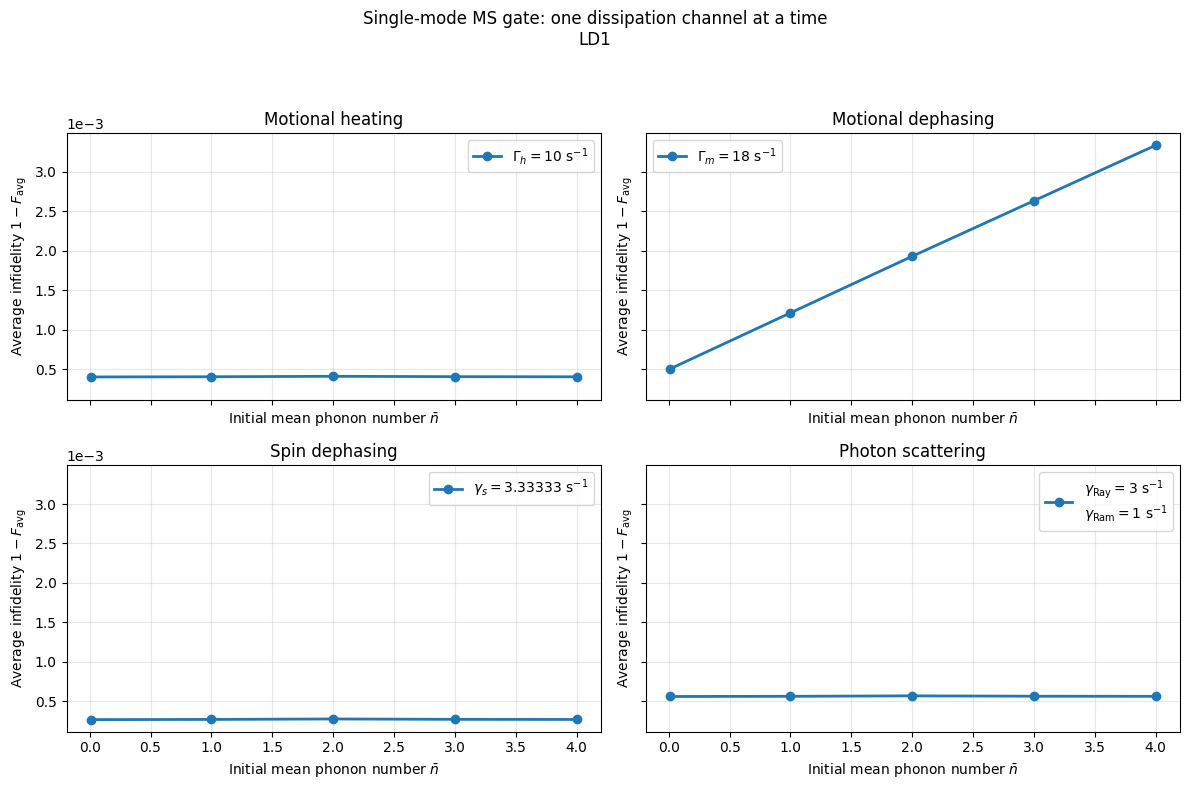

Saved: /Users/hirainoa/Desktop/量子/project/Moon_shot__高橋PJ/MS_gate_Hirai/results/single_mode_ms_gate_infidelity/single_noise/ld1


In [11]:
output_dir.mkdir(parents=True, exist_ok=True)

def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.generic):
        return json_safe(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return str(value)
    return value

run_config = {
    "simulation_parameters": SIMULATION_PARAMETERS,
    "noise_mode": "one_dissipation_channel_at_a_time",
    "case_simulation_parameters": case_parameters_by_source,
    "phonon_dim_scale": PHONON_DIM_SCALE,
    "phonon_dim_by_nbar": dimension_plan,
    "fidelity_definition": "F_avg = (4 * process_fidelity(channel, U_ideal) + 1) / 5",
    "ideal_gate": "exp(+1j*pi*XX/4)",
    "infidelity_clipped": False,
    "qutip_version": qp.__version__,
}
summary.to_csv(output_dir / "summary.csv", index=False)
case_rates.to_csv(output_dir / "case_rates.csv", index=False)
(output_dir / "config.json").write_text(
    json.dumps(json_safe(run_config), indent=2, ensure_ascii=False, allow_nan=False),
    encoding="utf-8",
)
np.savez_compressed(
    output_dir / "channels.npz",
    noise_source=summary["noise_source"].to_numpy(dtype=str),
    nbar=summary["nbar"].to_numpy(),
    superoperators=np.stack([
        channels_by_case[(row.noise_source, float(row.nbar))].full()
        for row in summary.itertuples(index=False)
    ]),
)

case_rate_labels = {
    "motional_heating": (
        rf"$\Gamma_h = {case_parameters_by_source['motional_heating']['heating_rate_phys']:g}" + r"\ \mathrm{s}^{-1}$"
    ),
    "motional_dephasing": (
        rf"$\Gamma_m = {case_parameters_by_source['motional_dephasing']['dephasing_rate_phys']:g}" + r"\ \mathrm{s}^{-1}$"
    ),
    "spin_dephasing": (
        rf"$\gamma_s = {1.0 / case_parameters_by_source['spin_dephasing']['T2_star']:.6g}" + r"\ \mathrm{s}^{-1}$"
    ),
    "photon_scattering": (
        rf"$\gamma_{{\rm Ray}} = {case_parameters_by_source['photon_scattering']['rayleigh_rate_phys']:g}" + r"\ \mathrm{s}^{-1}$"
        + "\n"
        + rf"$\gamma_{{\rm Ram}} = {case_parameters_by_source['photon_scattering']['raman_rate_phys']:g}" + r"\ \mathrm{s}^{-1}$"
    ),
}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
ld_label = r"LD2: relative $O(\eta^2)$ correction" if SIMULATION_PARAMETERS["use_full_order"] else "LD1"
fig.suptitle(f"Single-mode MS gate: one dissipation channel at a time\n{ld_label}")
for ax, (noise_source, case) in zip(axes.flat, NOISE_CASES.items()):
    data = summary.loc[summary["noise_source"] == noise_source].sort_values("nbar")
    ax.plot(
        data["nbar"], data["infidelity"], "o-", linewidth=2,
        label=case_rate_labels[noise_source],
    )
    ax.set_title(case["title"])
    ax.set_xlabel(r"Initial mean phonon number $\bar n$")
    ax.set_ylabel(r"Average infidelity $1-F_{\mathrm{avg}}$")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(output_dir / "single_noise_infidelity_vs_nbar.png", dpi=220)
plt.show()

print(f"Saved: {output_dir.resolve()}")
